# 02 — Selección del grupo: correlación, Engle–Granger y Johansen

**Dueño:** Gonzalo Cano (GC) · **Revisor:** Juan Manuel Espinosa (JME) · Guía: `docs/instrucciones/02_cointegracion.md`

Este notebook **solo muestra** lo que calcula `python main.py` (etapa 2). Lee los artefactos de `artifacts/` y llama
funciones de `cointegration/`; no contiene lógica propia. Todo lo que se estima aquí usa **solo entrenamiento**
(2012-01-03 → 2020-11-19).

**Dos iteraciones de la selección** (detalle en `docs/decisiones.md`):
1. **Iteración 1:** universos de petroleras y oro, grupos de 4, elección por mayor traza/crítico → GLD-GDX-AEM-FNV.
   Perdió la cointegración en validación (su spread llegó a ≈ 12 desviaciones de train).
2. **Iteración 2 (la vigente):** tras un proceso de búsqueda (prueba anidada, hiperparámetros, recalibración, un solo
   sector) y con autorización del profesor, solo el universo de oro, con **pares, tercias y cuartetos**. Grupo
   elegido: la tercia **GLD-GDX-B**, que sobrevive a todas las etapas del embudo.

| # | Etapa | Regla |
|---|---|---|
| 2 | Correlación | media de las correlaciones por pares (móvil 252 d, rendimientos log) > 0.7 → **elimina** |
| 3 | Engle–Granger | pares y grupo, p < 0.05 → **solo prioriza** |
| 4 | Johansen | la traza rechaza r = 0 al 95 % → **elimina** |
| 5 | Vector | entre las r̂ columnas con vida media en [5, 60] días, menor p ADF |
| 6 | Validación | ADF del spread p < 0.05 y vida media en [5, 60] días → **elimina** |
| 7 | Estabilidad | Johansen en cada mitad de train y Johansen móvil → se reporta |
| — | Elección | iteración 1: mayor traza/crítico; iteración 2: GLD-GDX-B (`CHOSEN_GROUP`), con fundamento económico |

In [1]:
import json
import sys
from math import comb
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from cointegration.engle_granger import engle_granger, pairwise_engle_granger
from cointegration.johansen import ANCHOR_TICKER, ROLLING_WINDOW, SIGN_CONVENTION, build_spread, summarize_rolling
from cointegration.selection import CORR_THRESHOLD, HALF_LIFE_RANGE
from cointegration.universe import UNIVERSES, all_tickers
from data.clean import clean_prices
from data.download import load_prices
from data.split import load_split_dates, slice_split
from main import ARTIFACTS, DATA_SNAPSHOT, END_DATE, FIGURES, START_DATE

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

table = pd.read_csv(ARTIFACTS / "selection_table.csv")
summary = json.loads((ARTIFACTS / "johansen_summary.json").read_text())
comparison = pd.read_csv(ARTIFACTS / "vector_comparison.csv")
rolling = pd.read_parquet(ARTIFACTS / "rolling_eigenvector.parquet")

split_dates = load_split_dates(ARTIFACTS / "split_dates.json")
prices, _ = clean_prices(load_prices(all_tickers(), START_DATE, END_DATE, DATA_SNAPSHOT))
train = slice_split(prices, split_dates, "train")
print(f"Entrenamiento: {train.index[0].date()} → {train.index[-1].date()} ({len(train)} días)")

Entrenamiento: 2012-01-03 → 2020-11-19 (2237 días)


## Paso 1 — Universo y número de grupos probados

Universo activo: oro y mineras (`cointegration/universe.py`, `ACTIVE_UNIVERSES`). Se prueban **todos** los pares,
tercias y cuartetos: C(8, 2) + C(8, 3) + C(8, 4) = 28 + 56 + 70 = 154. Ese total (y los 196 de la iteración 1) es el
que se reporta para la discusión de pruebas múltiples.

In [2]:
from cointegration.selection import GROUP_SIZES
from cointegration.universe import active_universes

counts = pd.DataFrame({
    name: {"activos": len(spec["tickers"]), **{f"grupos de {k}": comb(len(spec["tickers"]), k) for k in GROUP_SIZES},
           "tickers": ", ".join(spec["tickers"])}
    for name, spec in active_universes().items()
}).T
print("Total de grupos evaluados:", len(table))
counts

Total de grupos evaluados: 154


,activos,grupos de 2,grupos de 3,grupos de 4,tickers
oro,8,28,56,70,"GLD, GDX, NEM, AEM, KGC, B, AU, FNV"


## Resultado del embudo: en qué etapa se descartó cada grupo (por tamaño)

In [3]:
funnel = (table.assign(etapa=table["discard_stage"].fillna("sobrevive"))
          .groupby(["size", "etapa"], sort=True).size().unstack(fill_value=0))
funnel

etapa,2_correlacion,4_johansen,6_validacion,sobrevive
size,,,,
2,6,15,4,3
3,8,36,5,7
4,4,57,0,9


## Paso 2 — Correlación móvil de rendimientos

La correlación es solo una heurística: se calcula sobre **rendimientos** (la de dos precios I(1) es alta casi siempre).
En el universo de oro casi todos los grupos pasan 0.7 (la mediana por grupo es ≈ 0.74 en los tres tamaños); en la
iteración 1, las petroleras casi nunca la pasaban.

In [4]:
table.groupby("size")[["corr_mean", "corr_min_pair", "corr_frac_above"]].describe().T.round(3)

size                        2       3       4
corr_mean       count 28.0000 56.0000 70.0000
                mean   0.7490  0.7490  0.7490
                std    0.0650  0.0470  0.0360
                min    0.6570  0.6750  0.6800
                25%    0.7040  0.7090  0.7180
                50%    0.7280  0.7410  0.7500
                75%    0.7850  0.7910  0.7790
                max    0.8780  0.8400  0.8190
corr_min_pair   count 28.0000 56.0000 70.0000
                mean   0.7490  0.7010  0.6840
                std    0.0650  0.0330  0.0230
                min    0.6570  0.6570  0.6570
                25%    0.7040  0.6760  0.6740
                50%    0.7280  0.7020  0.6760
                75%    0.7850  0.7230  0.7020
                max    0.8780  0.7860  0.7540
corr_frac_above count 28.0000 56.0000 70.0000
                mean   0.7080  0.7470  0.7690
                std    0.2160  0.1880  0.1560
                min    0.2700  0.2740  0.4430
                25%    0.5830  0.6220  0.6470
                50%    0.6710  0.7120  0.7540
                75%    0.8740  0.9460  0.9130
                max    1.0000  1.0000  1.0000

**Correlación por par vs regla de grupo.** A nivel par, cada correlación es el promedio en el tiempo de la
correlación móvil de 252 días. La regla del embudo (sesión 14) exige que la **media de los pares** del grupo supere 0.7.
El grupo elegido la cumple también con la regla más estricta: sus 3 pares superan 0.7 (el más débil, 0.716) y la media
del grupo supera 0.7 el 100 % de los días. Ver `docs/decisiones.md`.

In [5]:
from cointegration.correlation import rolling_pairwise_correlation
from cointegration.selection import CORR_WINDOW

pair_level = pd.DataFrame({
    name: rolling_pairwise_correlation(np.log(train[spec["tickers"]]).diff().dropna(), CORR_WINDOW).mean().describe()
    for name, spec in active_universes().items()
}).T
pair_level.round(3)

,count,mean,std,min,25%,50%,75%,max
oro,28.0000,0.7490,0.0650,0.6570,0.7040,0.7280,0.7850,0.8780


## Paso 3 — Engle–Granger (prioriza, no elimina)

Pares del universo de oro en entrenamiento (p-value de MacKinnon, ambas direcciones). Nótese que **GLD-GDX**, el par
clásico de Chan (2013), no sale cointegrado en este periodo; **GDX-B** sí (p ≈ 0.04).

In [6]:
gold = UNIVERSES["oro"]["tickers"]
pairs_gold = pairwise_engle_granger(np.log(train[gold])).sort_values("pvalue_min")
pairs_gold.head(10)

,asset_1,asset_2,pvalue_1_on_2,pvalue_2_on_1,pvalue_min
22,KGC,B,0.0044,0.0045,0.0044
9,GDX,KGC,0.0211,0.0220,0.0211
10,GDX,B,0.0475,0.0387,0.0387
13,NEM,AEM,0.0552,0.0499,0.0499
17,NEM,FNV,0.0843,0.0827,0.0827
25,B,AU,0.1363,0.1213,0.1213
23,KGC,AU,0.1300,0.1478,0.1300
8,GDX,AEM,0.1315,0.6563,0.1315
21,AEM,FNV,0.1342,0.2170,0.1342
3,GLD,KGC,0.3564,0.1425,0.1425


Regresión de Engle–Granger del grupo elegido con cada activo como dependiente. La bandera `spurious_flag`
(R² > Durbin–Watson, sesión 12) aparece en todas: las regresiones en niveles de series I(1) siempre la levantan,
por eso EG no basta y el criterio definitivo es Johansen. Con GDX o B como dependiente el grupo sí es cointegrado por
EG (p = 0.016 y 0.031); con GLD como dependiente no (p = 0.53): el resultado de EG depende de la dirección.

In [7]:
chosen_tickers = summary["tickers"]
log_chosen = np.log(train[chosen_tickers])
pd.DataFrame([
    {"dependiente": r.dependent, **{f"h_{t}": h for t, h in zip(r.regressors, r.hedge_ratios)},
     "R2": r.r_squared, "DW": r.durbin_watson, "ADF": r.adf_stat, "p-value": r.pvalue, "espuria": r.spurious_flag}
    for r in (engle_granger(log_chosen, t) for t in chosen_tickers)
])

,dependiente,h_GDX,h_B,R2,DW,ADF,p-value,espuria,h_GLD
0,GLD,0.6235,-0.1610,0.8898,0.0321,-2.4133,0.5301,True,NaN
1,GDX,NaN,0.5017,0.9714,0.0476,-4.1458,0.0160,True,0.8036
2,B,1.5295,NaN,0.9486,0.0347,-3.9204,0.0309,True,-0.6329


## Paso 4 — Johansen: todos los grupos

`trace_ratio` = LR_traza(0) / valor crítico al 95 %. Arriba de 1 se rechaza "no hay cointegración". `trace_rank` es
la posición de cada sobreviviente por esa razón (la regla de elección de la iteración 1).

In [8]:
cols = ["size", "group", "corr_mean", "eg_significant_pairs", "k_ar_diff", "trace_0", "trace_cv95_0",
        "trace_ratio", "trace_rank", "rank_trace", "rank_maxeig", "rank_trace_99", "spread_adf_pvalue", "half_life",
        "rank_trace_first_half", "rank_trace_second_half", "discard_stage", "chosen"]
table.loc[table["survives"], cols].sort_values("trace_ratio", ascending=False).round(3)

,size,group,corr_mean,eg_significant_pairs,k_ar_diff,trace_0,trace_cv95_0,trace_ratio,trace_rank,rank_trace,rank_maxeig,rank_trace_99,spread_adf_pvalue,half_life,rank_trace_first_half,rank_trace_second_half,discard_stage,chosen
22,2,KGC-B,0.7650,1,1,20.6080,15.4940,1.3300,1.0000,2,2,1,0.0010,55.6740,0,0,NaN,False
92,4,GLD-GDX-AEM-FNV,0.7730,0,1,61.2850,47.8540,1.2810,2.0000,1,1,1,0.0000,25.3360,1,1,NaN,False
10,2,GDX-B,0.8780,1,1,18.7680,15.4940,1.2110,3.0000,2,0,0,0.0150,54.8490,0,0,NaN,False
31,3,GLD-GDX-B,0.7930,1,1,35.8230,29.7960,1.2020,4.0000,1,1,1,0.0010,29.1130,1,0,NaN,True
9,2,GDX-KGC,0.8510,1,1,18.6010,15.4940,1.2010,5.0000,2,0,0,0.0050,52.4610,0,0,NaN,False
93,4,GLD-GDX-KGC-B,0.7780,3,1,55.6590,47.8540,1.1630,6.0000,1,1,1,0.0000,28.8070,0,1,NaN,False
97,4,GLD-GDX-B-FNV,0.7690,1,1,54.0030,47.8540,1.1280,7.0000,1,1,0,0.0000,24.8870,1,1,NaN,False
88,4,GLD-GDX-NEM-FNV,0.7510,0,1,53.7990,47.8540,1.1240,8.0000,1,1,0,0.0010,36.8090,1,1,NaN,False
58,3,GDX-KGC-B,0.8320,3,1,33.2720,29.7960,1.1170,9.0000,3,0,0,0.0010,55.8300,0,0,NaN,False
59,3,GDX-KGC-AU,0.7960,1,1,32.7520,29.7960,1.0990,10.0000,3,0,0,0.0080,45.6320,0,1,NaN,False


## Grupo elegido — estadísticos de traza y máximo eigenvalor

In [9]:
print(f"Grupo: {'-'.join(chosen_tickers)} ({summary['universe']}), k_ar_diff = {summary['k_ar_diff']} "
      f"(BIC), det_order = {summary['det_order']}, T = {summary['n_obs']}")
johansen_table = pd.concat({"traza": pd.DataFrame(summary["trace"]).set_index("r0"),
                            "máx. eigenvalor": pd.DataFrame(summary["max_eigen"]).set_index("r0")}, axis=1)
johansen_table.index = [f"r ≤ {r}" for r in johansen_table.index]
print("Eigenvalores:", np.round(summary["eigenvalues"], 5))
print(f"r̂ (traza) = {summary['rank_trace']}, r̂ (máx. eigenvalor) = {summary['rank_maxeig']}")
johansen_table

Grupo: GLD-GDX-B (oro), k_ar_diff = 1 (BIC), det_order = 0, T = 2237
Eigenvalores: [0.01225 0.00321 0.00049]
r̂ (traza) = 1, r̂ (máx. eigenvalor) = 1


traza                                   máx. eigenvalor                                  
         stat    cv90    cv95    cv99 reject_95            stat    cv90    cv95    cv99 reject_95
r ≤ 0 35.8227 27.0669 29.7961 35.4628      True         27.5424 18.8928 21.1314 25.8650      True
r ≤ 1  8.2803 13.4294 15.4943 19.9349     False          7.1857 12.2971 14.2639 18.5200     False
r ≤ 2  1.0946  2.7055  3.8415  6.6349     False          1.0946  2.7055  3.8415  6.6349     False

## Pasos 5 y 6 — Comparación de vectores y validación del spread

Spread de **cada** eigenvector (normalizado sobre su pata de mayor |β|), con ADF y vida media. Solo el vector 1 está
dentro del rango y es el único con vida media operable (29 días; los otros, 137 y 321).

In [10]:
comparison

,vector,eigenvalue,in_rank,anchor,beta_GLD,beta_GDX,beta_B,adf_stat,adf_pvalue,half_life,operable,valid
0,1,0.0122,True,GDX,-0.8266,1.0000,-0.4481,-4.1290,0.0009,29.1128,True,True
1,2,0.0032,False,B,-0.9192,-0.6666,1.0000,-2.8749,0.0483,137.4654,False,False
2,3,0.0005,False,GLD,1.0000,-0.2952,0.0310,-0.5821,0.8750,320.6048,False,False


In [11]:
beta = pd.Series(summary["beta_normalized"])
print(f"Pata ancla: {summary['anchor']} (constante ANCHOR_TICKER = {ANCHOR_TICKER!r}); convención: {SIGN_CONVENTION}")
print("β̃ =", beta.round(4).to_dict())
print(f"c (media del spread en train) = {summary['intercept_c']:.4f}")
print(f"ADF del spread: estadístico {summary['spread_adf_stat']:.3f}, p = {summary['spread_adf_pvalue']:.5f}")
print(f"Vida media: {summary['half_life_days']:.1f} días (rango operable {HALF_LIFE_RANGE})")
print("Orden de integración de cada activo:")
pd.DataFrame(summary["integration_order"]).T

Pata ancla: GDX (constante ANCHOR_TICKER = 'GDX'); convención: beta_anchor = +1 (largo el spread = comprar los activos con beta > 0, vender los de beta < 0)
β̃ = {'GLD': -0.8266, 'GDX': 1.0, 'B': -0.4481}
c (media del spread en train) = -2.0660
ADF del spread: estadístico -4.129, p = 0.00087
Vida media: 29.1 días (rango operable (5.0, 60.0))
Orden de integración de cada activo:


,adf_pvalue_level,adf_pvalue_diff,is_I1
GLD,0.6926,0.0000,True
GDX,0.1890,0.0000,True
B,0.1998,0.0000,True


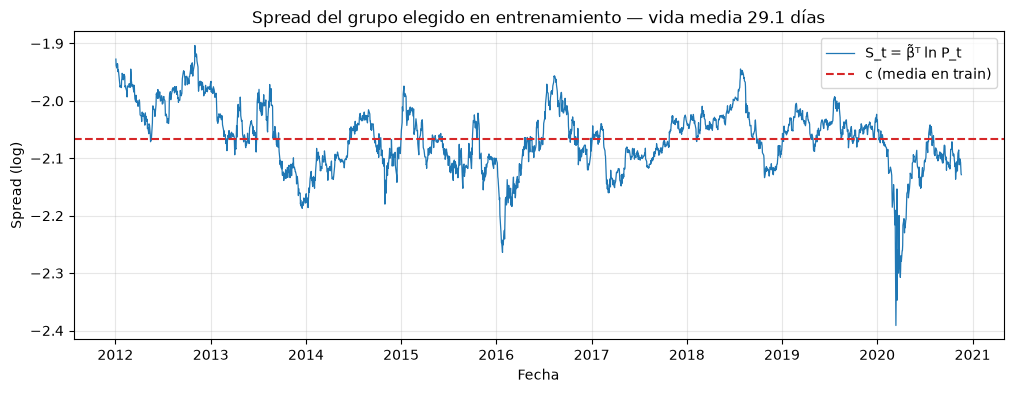

In [12]:
spread = build_spread(log_chosen, beta[chosen_tickers].to_numpy())
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(spread.index, spread, linewidth=0.9, label="S_t = β̃ᵀ ln P_t")
ax.axhline(summary["intercept_c"], color="tab:red", linestyle="--", label="c (media en train)")
ax.set_title(f"Spread del grupo elegido en entrenamiento — vida media {summary['half_life_days']:.1f} días")
ax.set_xlabel("Fecha"); ax.set_ylabel("Spread (log)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## Paso 7 — Estabilidad

Johansen móvil con ventana de 504 días y paso de 21, k fijo al de entrenamiento y la misma pata ancla. Cada ventana
usa solo datos pasados; se muestra toda la muestra como **diagnóstico**.

In [13]:
summarize_rolling(rolling, chosen_tickers)

,GLD_median,GDX_median,B_median,GLD_std,GDX_std,B_std,frac_windows_rank_ge_1,n_windows
split,,,,,,,,
train,-2.0710,1.0000,-0.1706,15.8527,0.0000,2.1866,0.1446,83
test,-0.9679,1.0000,-0.6156,1.9104,0.0000,0.6616,0.3056,36
validation,-0.8909,1.0000,-0.4849,0.2328,0.0000,0.4077,0.0571,35


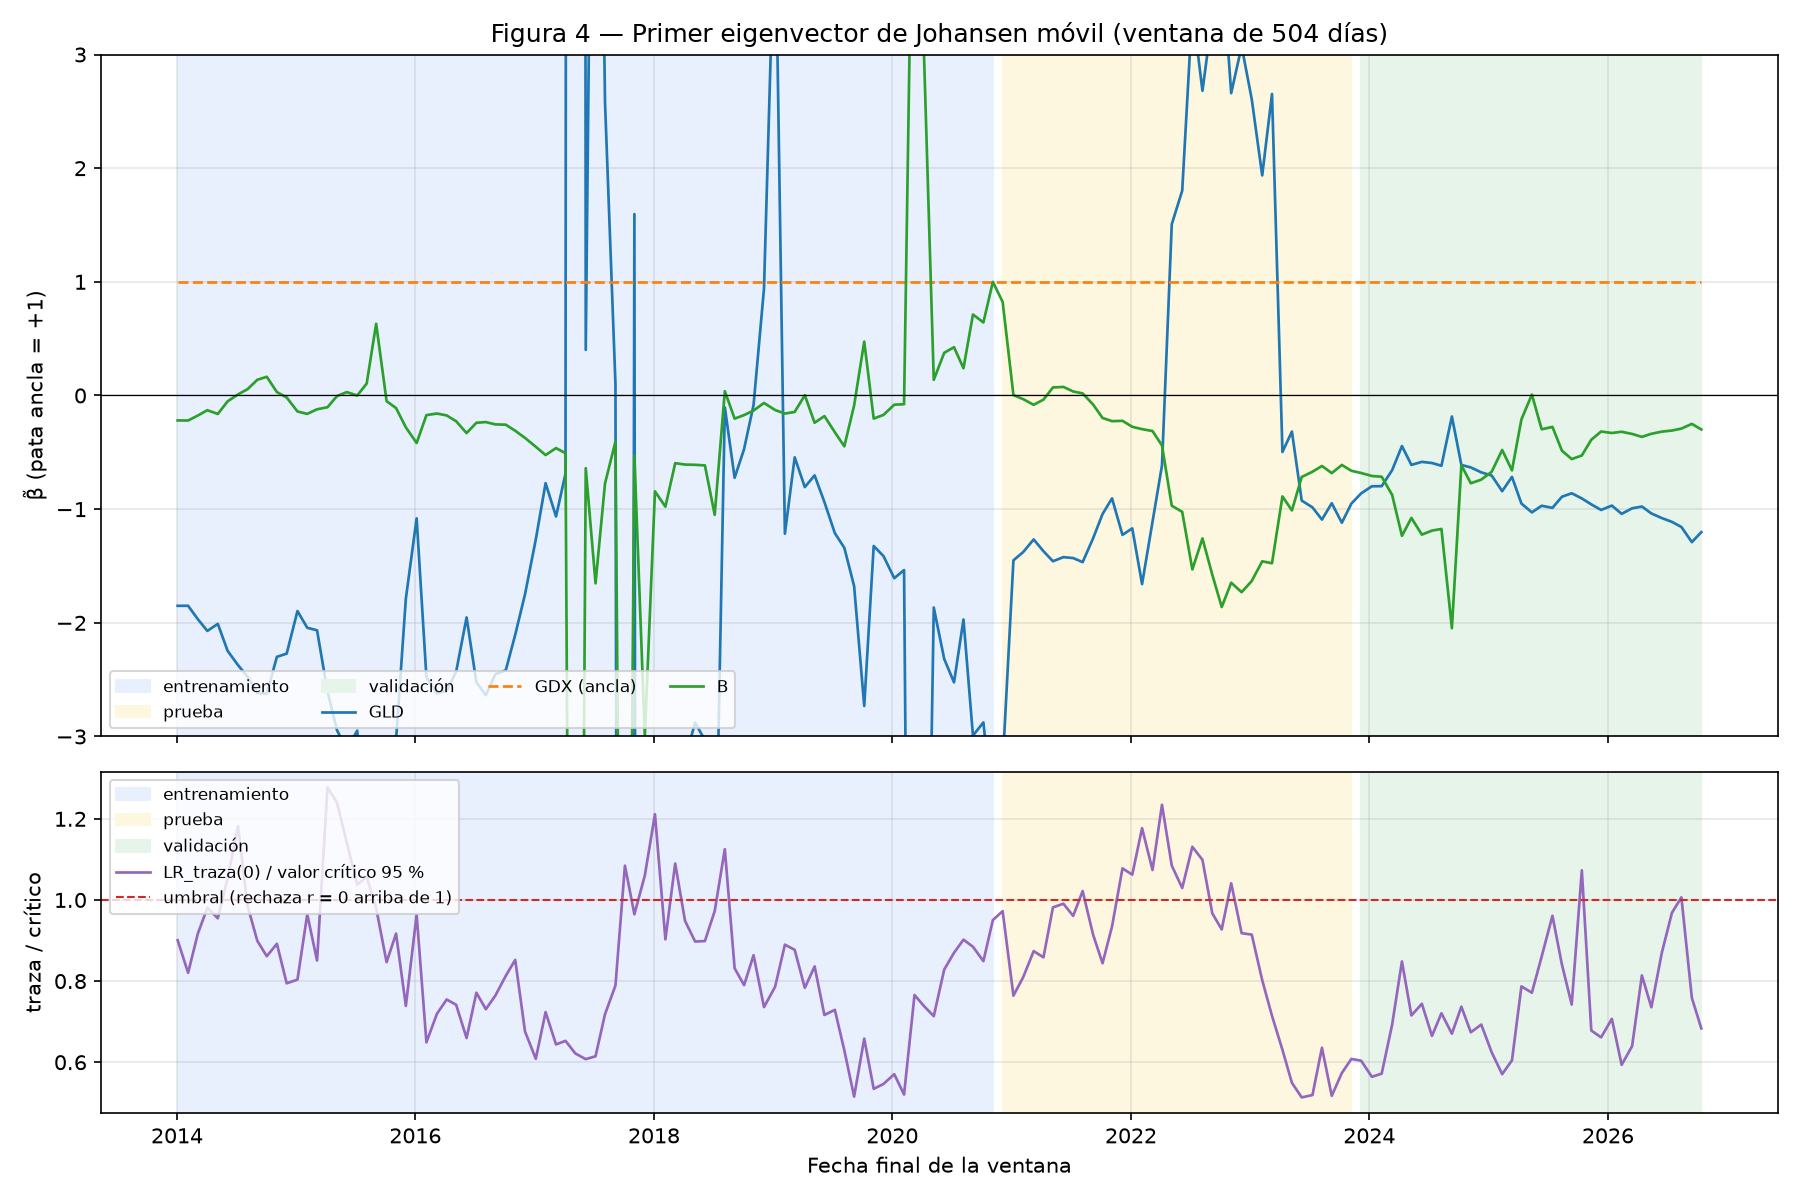

In [14]:
display(Image(filename=str(FIGURES / "fig04_eigenvector_movil.png")))

## Pruebas múltiples

In [15]:
mt = summary["multiple_testing"]
pd.DataFrame({**{f"tamaño {k}": v for k, v in mt["by_size"].items()}, "total": mt["total"]}).T

,groups_tested,johansen_reject_95,johansen_reject_99,expected_false_positives_95,pass_correlation,survive_all_stages,bonferroni_alpha
tamaño 2,28.0000,7.0000,1.0000,1.4000,22.0000,3.0000,0.0018
tamaño 3,56.0000,14.0000,1.0000,2.8000,48.0000,7.0000,0.0009
tamaño 4,70.0000,9.0000,2.0000,3.5000,66.0000,9.0000,0.0007
total,154.0000,30.0000,4.0000,7.7000,136.0000,19.0000,0.0003


## Discusión

- **Pruebas múltiples.** En la iteración 2 se probaron 154 grupos. Al 95 %, Johansen rechaza r = 0 en 30 cuando el
  azar daría ≈ 7.7 (7 de 28 pares, 14 de 56 tercias, 9 de 70 cuartetos). Al 99 % quedan 4, y la tercia elegida es una
  de ellas (traza 35.8 > 35.5). Sumando la iteración 1, el proceso completo probó 280 grupos distintos. Con
  Bonferroni las tablas de statsmodels no alcanzan para afirmarlo; la defensa es el racional económico, reportar el
  total de grupos y la estabilidad fuera de muestra.
- **Por qué la tercia.** Queda 4.ª de 19 por traza/crítico (la regla de la iteración 1 elegiría el par KGC-B, que
  revierte con vida media de 56 días). El fundamento es económico: GDX es el ETF de mineras y Barrick una de sus
  posiciones más grandes, así que el metal, el ETF y su mayor componente comparten la tendencia casi de forma
  mecánica. En la iteración 1, AEM y FNV (regalías) se despegaron del oro en 2024–2026 y rompieron la relación.
- **Lectura económica de β̃.** Con GDX = +1: largo el spread = comprar el ETF de mineras y vender oro (GLD, 0.83) y
  Barrick (B, 0.45), en proporción a |β̃_i|. Es la exposición apalancada de las mineras contra el metal y contra su
  componente principal.
- **Estabilidad.** La tercia rechaza r = 0 en la primera mitad de entrenamiento pero no en la segunda (6 de los 19
  sobrevivientes rechazan en ambas). El Johansen móvil de 2 años es significativo en pocas ventanas (15 % en train,
  31 % en prueba, 6 % en validación), aunque en validación los pesos móviles son mucho más estables que en train
  (desviación de β̃_GLD 0.23 vs 15.9). Fuera de muestra la relación **se debilita sin romperse** (notebook 03): el
  spread estático se desplaza ≈ 2 desviaciones y el ECT dinámico del filtro 1 sigue centrado y estacionario.

## Para el filtro 1 (parte 03)

- Inicialización: β_0 = β̃ de `johansen_summary.json` (`beta_normalized`), pata ancla **GDX** = +1, en **log-precios**.
- Estado del filtro 1: z_t = (c_t, β_t^{GLD}, β_t^{B}), y_t = ln P_t^{GDX}.
- `artifacts/prices.parquet` lo escribe `main.py`: GLD, GDX, B con la columna `split`.

## Resumen de resultados (parte 02)

**Pregunta:** ¿qué grupo del universo de oro comparte una tendencia estocástica común en entrenamiento (2012-01-03 →
2020-11-19), y con qué vector de pesos? Todo se estimó solo con entrenamiento.

**Embudo de la iteración 2 (154 grupos del universo de oro)**

| Tamaño | Descartados por correlación | Por Johansen | Por validación del spread | Sobreviven |
|---|---|---|---|---|
| Pares (28) | 6 | 15 | 4 | 3 |
| Tercias (56) | 8 | 36 | 5 | 7 |
| Cuartetos (70) | 4 | 57 | 0 | 9 |

**Grupo elegido: GLD – GDX – B** (oro físico, ETF de mineras, Barrick)

| Resultado | Valor |
|---|---|
| Johansen, traza r = 0 | 35.8 vs 29.8 (95 %) y 35.5 (99 %) → se rechaza |
| Johansen, máx. eigenvalor r = 0 | 27.5 vs 21.1 (95 %) → se rechaza |
| Rango r̂ | 1 por ambas pruebas (k_ar_diff = 1 por BIC, constante) |
| Vector normalizado β̃ (ancla GDX = +1) | GLD −0.827, GDX +1.000, B −0.448 |
| Constante c (media del spread en train) | −2.066 |
| ADF del spread | −4.13, p = 0.0009 → estacionario |
| Vida media | 29.1 días (rango operable 5–60) |
| Correlación media del grupo | 0.793 (supera 0.7 el 100 % de los días; par más débil 0.716) |
| Los 3 activos son I(1) | sí (ADF en niveles no rechaza; en diferencias sí) |
| Posición por traza/crítico | 4.ª de 19 sobrevivientes |

- **Interpretación:** largo el spread = comprar GDX, vender GLD y B.
- **Iteración 1 (referencia):** GLD-GDX-AEM-FNV, traza 61.3 vs 47.9, vida media 25.3 días; perdió la cointegración en
  validación.

**Pruebas múltiples:** 30 de 154 grupos rechazan r = 0 al 95 % (≈ 7.7 por azar); al 99 % quedan 4 y la tercia es una
de ellos. Proceso completo: 280 grupos distintos.

**Estabilidad:** rechaza en la primera mitad de train y no en la segunda; el Johansen móvil de 2 años rara vez es
significativo (figura 4). Fuera de muestra la relación se debilita pero no se rompe, y el filtro 1 absorbe la deriva.

**Siguiente paso:** el filtro 1 (parte 03) arranca con β̃ como inicialización sobre `artifacts/prices.parquet`.